# AI-driven Water Quality Monitoring: Person A (Data & EDA)
**Goal:** predict water potability from physicochemical measurements.
**This notebook covers:** data collection, cleaning, missing-value handling, class imbalance, feature analysis.
**Deliverables for Person B:** `water_potability_clean.csv`, `train.csv`, `test.csv`, `eda_summary.json`

**Dataset:** Kaggle *Water Potability* (`adityakadiwal/water-potability`), 3276 samples, 9 features + target `Potability` (1 = safe, 0 = not safe).

## 1. Setup

In [18]:
!pip -q install kagglehub
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)

## 2. Data collection
Works on Google Colab (via `kagglehub`, no API key needed for public datasets) and on Kaggle notebooks.

In [19]:
def load_water_data():
    # Kaggle notebook (after "Add Input" -> water-potability)
    for p in ["/kaggle/input/water-potability/water_potability.csv"]:
        if os.path.exists(p):
            return pd.read_csv(p)
    # Colab / local
    try:
        import kagglehub
        path = kagglehub.dataset_download("adityakadiwal/water-potability")
        return pd.read_csv(os.path.join(path, "water_potability.csv"))
    except Exception as e:
        print("kagglehub failed:", e)
    # Manual fallback: upload water_potability.csv in Colab
    from google.colab import files
    up = files.upload()
    return pd.read_csv(list(up.keys())[0])

df_raw = load_water_data()
df = df_raw.copy()
print(df.shape)
df.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 3. First look

In [20]:
df.info()
display(df.describe().T)
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


Duplicate rows: 0


## 4. Domain validity checks
Catch physically impossible values (pH must be 0-14, no negative concentrations).

In [21]:
features = [c for c in df.columns if c != "Potability"]
print("pH outside [0,14]:", ((df.ph < 0) | (df.ph > 14)).sum())
print("Negative values per feature:")
print((df[features] < 0).sum())
print("Target values:", df.Potability.unique())

pH outside [0,14]: 0
Negative values per feature:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64
Target values: [0 1]


## 5. Missing values

,missing,pct
ph,491,14.99
Sulfate,781,23.84
Trihalomethanes,162,4.95


Rows with at least one missing value: 1265 (38.6%)


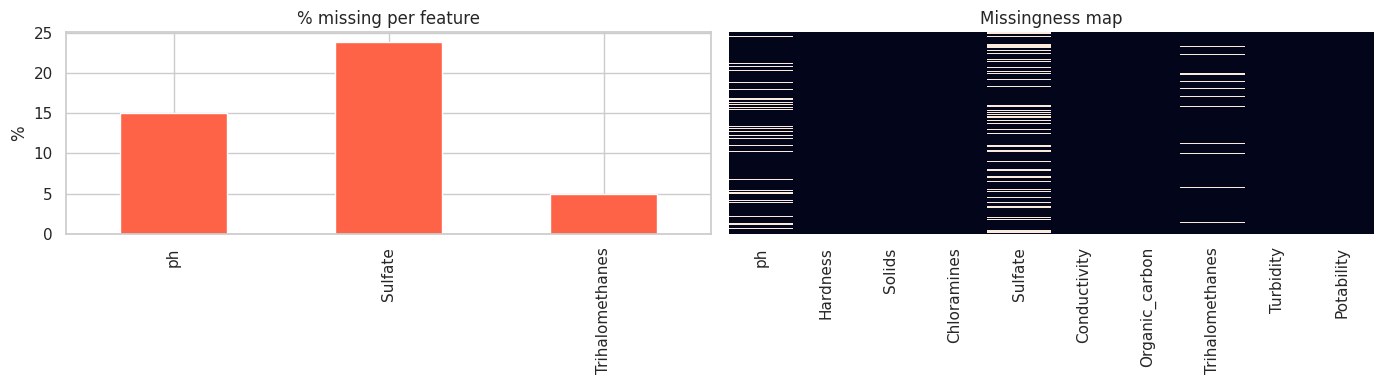

In [22]:
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
display(miss[miss.missing > 0])
print("Rows with at least one missing value:", df.isna().any(axis=1).sum(), f"({df.isna().any(axis=1).mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
miss[miss.missing > 0].pct.plot.bar(ax=ax[0], color="tomato"); ax[0].set_title("% missing per feature"); ax[0].set_ylabel("%")
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax[1]); ax[1].set_title("Missingness map")
plt.tight_layout(); plt.savefig(f"{OUT}/missing.png", dpi=120); plt.show()

In [23]:
# Is missingness related to the target? (if not, it's likely random -> simple imputation is safe)
for c in ["ph", "Sulfate", "Trihalomethanes"]:
    ct = pd.crosstab(df[c].isna(), df.Potability)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"{c:16s} missing vs Potability  chi2 p-value = {p:.3f}")

ph               missing vs Potability  chi2 p-value = 0.159
Sulfate          missing vs Potability  chi2 p-value = 0.348
Trihalomethanes  missing vs Potability  chi2 p-value = 0.203


## 6. Class imbalance

            count   pct
Potability             
0            1998  61.0
1            1278  39.0
Imbalance ratio (majority/minority): 1.56


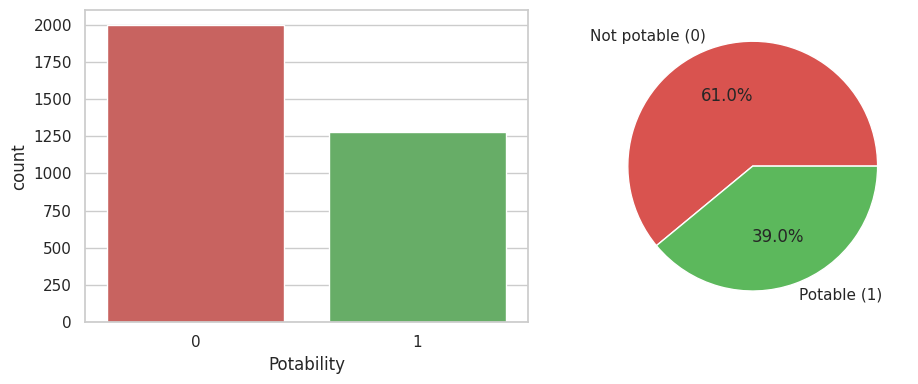

In [24]:
counts = df.Potability.value_counts().sort_index()
pct = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "pct": pct}))
print(f"Imbalance ratio (majority/minority): {counts.max()/counts.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Potability", data=df, ax=ax[0], palette=["#d9534f", "#5cb85c"])
ax[1].pie(counts, labels=["Not potable (0)", "Potable (1)"], autopct="%1.1f%%", colors=["#d9534f", "#5cb85c"])
plt.tight_layout(); plt.savefig(f"{OUT}/class_balance.png", dpi=120); plt.show()

**Decision:** the imbalance is mild (~61/39). We do **not** resample the saved dataset, because resampling before the train/test split leaks data.
Person B should use `class_weight="balanced"` or SMOTE **inside** the training folds only, and judge models with F1 / ROC-AUC / PR-AUC, not accuracy alone.

## 7. Feature distributions and outliers

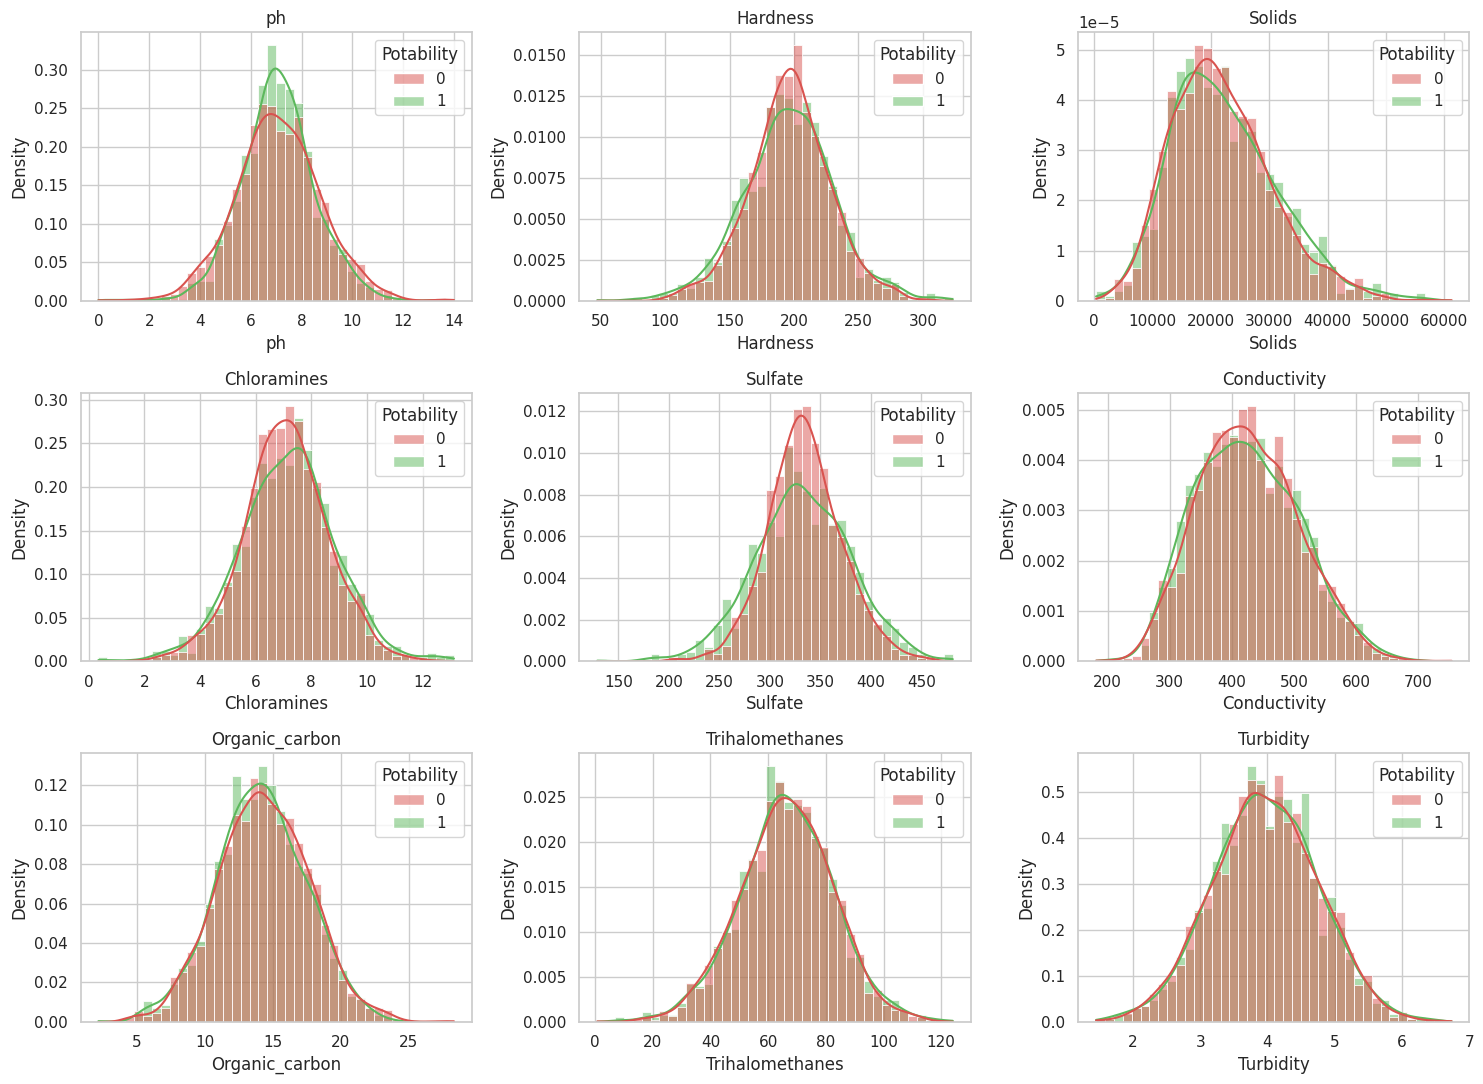

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), features):
    sns.histplot(data=df, x=c, hue="Potability", kde=True, bins=40, ax=ax, palette=["#d9534f", "#5cb85c"], stat="density", common_norm=False)
    ax.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT}/distributions.png", dpi=120); plt.show()

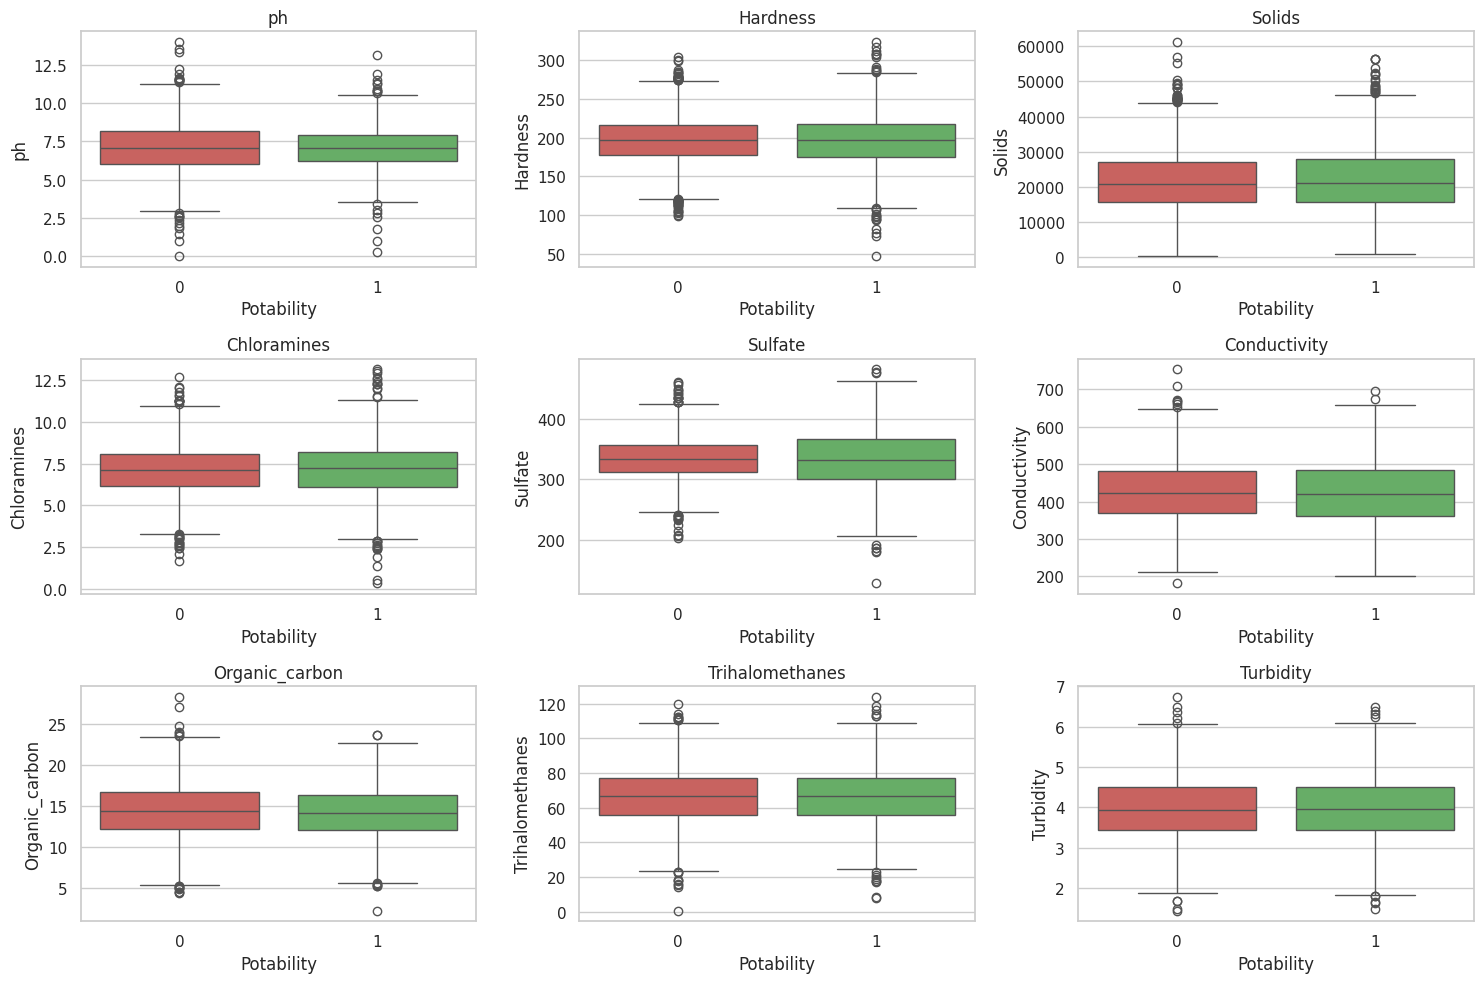

,n_outliers,pct,skew
feature,,,
ph,46,1.65,0.03
Hardness,83,2.53,-0.04
Solids,47,1.43,0.62
Chloramines,61,1.86,-0.01
Sulfate,41,1.64,-0.04
Conductivity,11,0.34,0.26
Organic_carbon,25,0.76,0.03
Trihalomethanes,33,1.06,-0.08
Turbidity,19,0.58,-0.01


In [26]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Potability", y=c, ax=ax, palette=["#d9534f", "#5cb85c"])
    ax.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT}/boxplots.png", dpi=120); plt.show()

# IQR outlier report
rows = []
for c in features:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append((c, n, round(n / df[c].notna().sum() * 100, 2), round(df[c].skew(), 2)))
outlier_report = pd.DataFrame(rows, columns=["feature", "n_outliers", "pct", "skew"]).set_index("feature")
outlier_report

Outliers here are mostly natural variation in water chemistry (not sensor errors; all values passed the validity check), so we **keep** them.
Tree models are robust to them. For linear/NN models Person B can apply scaling inside the pipeline.

## 8. Feature analysis

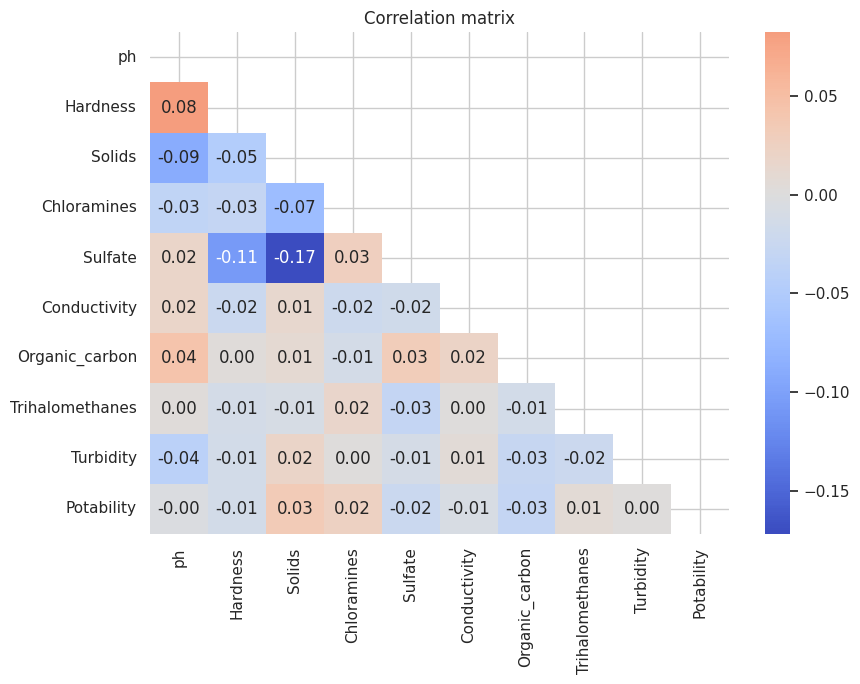

Max |corr| between two features: 0.172


In [27]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig(f"{OUT}/correlation.png", dpi=120); plt.show()

print("Max |corr| between two features:", round(float(corr.drop("Potability").drop("Potability", axis=1).abs().where(~np.eye(9, dtype=bool)).max().max()), 3))

In [28]:
# Univariate relevance: t-test (potable vs not), Mann-Whitney, mutual information
imp_tmp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(df[features]), columns=features)
mi = mutual_info_classif(imp_tmp, df.Potability, random_state=RANDOM_STATE)
res = []
for c, m in zip(features, mi):
    a = df.loc[df.Potability == 1, c].dropna(); b = df.loc[df.Potability == 0, c].dropna()
    res.append((c, df[[c, "Potability"]].corr().iloc[0, 1], stats.ttest_ind(a, b, equal_var=False).pvalue,
                stats.mannwhitneyu(a, b).pvalue, m))
feat_rel = pd.DataFrame(res, columns=["feature", "corr_with_target", "ttest_p", "mannwhitney_p", "mutual_info"]).set_index("feature")
feat_rel.sort_values("mutual_info", ascending=False).round(4)

,corr_with_target,ttest_p,mannwhitney_p,mutual_info
feature,,,,
Hardness,-0.0138,0.4421,0.5439,0.0266
Conductivity,-0.0081,0.6437,0.5523,0.0071
Organic_carbon,-0.0300,0.0845,0.1255,0.0040
Turbidity,0.0016,0.9280,0.9504,0.0031
Sulfate,-0.0236,0.2646,0.4050,0.0024
Solids,0.0337,0.0569,0.1333,0.0011
ph,-0.0036,0.8465,0.9084,0.0002
Chloramines,0.0238,0.1856,0.1529,0.0000
Trihalomethanes,0.0071,0.6918,0.7672,0.0000


In [29]:
# Multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = (imp_tmp - imp_tmp.mean()) / imp_tmp.std()
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=features, name="VIF").round(2)
vif

ph                 1.02
Hardness           1.02
Solids             1.04
Chloramines        1.01
Sulfate            1.04
Conductivity       1.00
Organic_carbon     1.00
Trihalomethanes    1.00
Turbidity          1.00
Name: VIF, dtype: float64

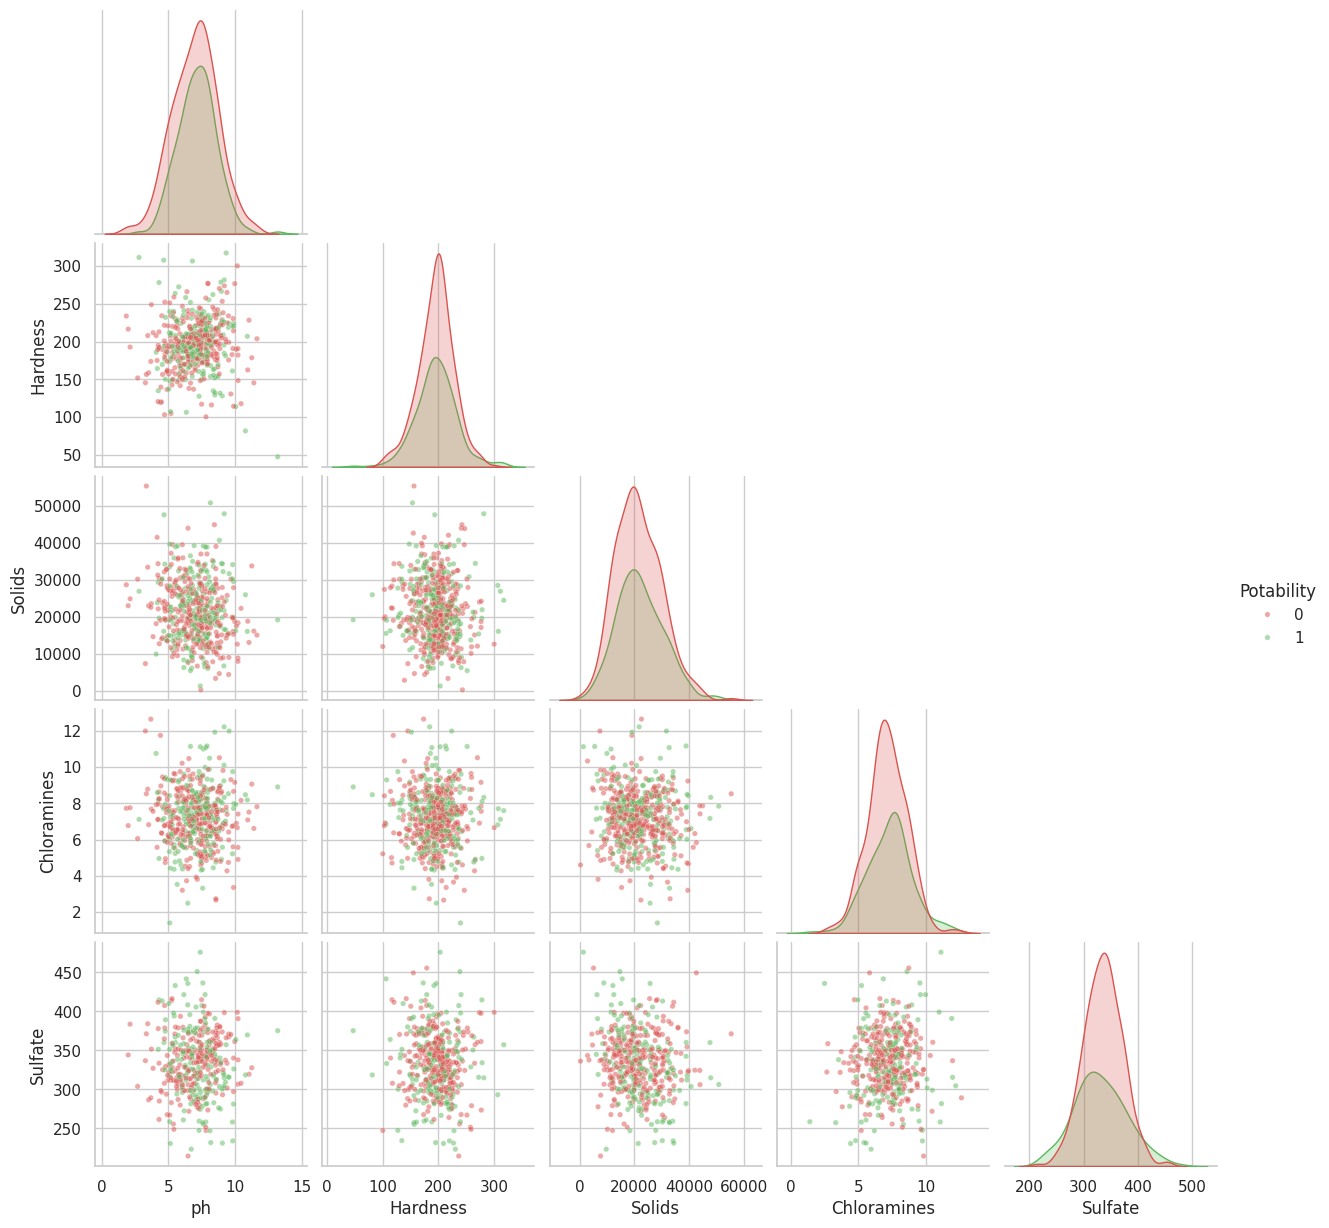

In [30]:
sns.pairplot(df.sample(600, random_state=RANDOM_STATE), vars=features[:5], hue="Potability", palette=["#d9534f", "#5cb85c"], corner=True, plot_kws={"alpha": .5, "s": 15})
plt.savefig(f"{OUT}/pairplot.png", dpi=100); plt.show()

**Takeaways:** features are weakly correlated with each other (low VIF, no redundancy to drop) and individually only weakly related to the target. This is a **hard, noisy** dataset; expect modest accuracy (roughly 60-70%). Person B should not expect miracles, and should report F1/AUC with cross-validation.

## 9. Cleaning and missing-value handling

In [31]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Removed duplicates:", len(df) - len(df_clean))

# Keep missing-indicator flags (missingness may carry signal)
for c in ["ph", "Sulfate", "Trihalomethanes"]:
    df_clean[f"{c}_was_missing"] = df_clean[c].isna().astype(int)

# (a) Full median-imputed file: convenient for quick EDA / baselines
imp_full = SimpleImputer(strategy="median")
df_full = df_clean.copy()
df_full[features] = imp_full.fit_transform(df_full[features])
assert df_full[features].isna().sum().sum() == 0
df_full.to_csv(f"{OUT}/water_potability_clean.csv", index=False)

# (b) Leakage-safe stratified split: imputer fitted on TRAIN only
X = df_clean.drop(columns="Potability"); y = df_clean.Potability
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
imp = SimpleImputer(strategy="median").fit(Xtr[features])
Xtr, Xte = Xtr.copy(), Xte.copy()
Xtr[features] = imp.transform(Xtr[features]); Xte[features] = imp.transform(Xte[features])
train = pd.concat([Xtr, ytr], axis=1); test = pd.concat([Xte, yte], axis=1)
train.to_csv(f"{OUT}/train.csv", index=False); test.to_csv(f"{OUT}/test.csv", index=False)

print("train:", train.shape, "| test:", test.shape)
print("train class %:", (ytr.value_counts(normalize=True) * 100).round(1).to_dict())
print("test  class %:", (yte.value_counts(normalize=True) * 100).round(1).to_dict())

Removed duplicates: 0
train: (2620, 13) | test: (656, 13)
train class %: {0: 61.0, 1: 39.0}
test  class %: {0: 61.0, 1: 39.0}


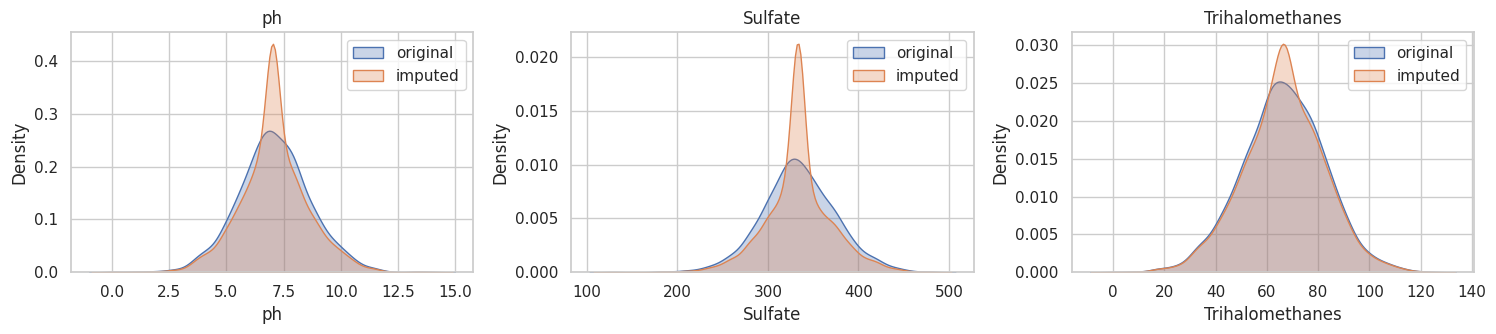

In [32]:
# Sanity check: imputation did not distort distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ["ph", "Sulfate", "Trihalomethanes"]):
    sns.kdeplot(df[c].dropna(), ax=ax, label="original", fill=True, alpha=.3)
    sns.kdeplot(df_full[c], ax=ax, label="imputed", fill=True, alpha=.3); ax.set_title(c); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/imputation_check.png", dpi=120); plt.show()